# 01 · From words to numbers: embeddings and a first LSTM

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/LSTM_emotion_recognition/blob/main/notebooks/01_text_to_numbers_embeddings_lstm.ipynb)

**After this notebook you will be able to** explain how a computer turns a movie review into numbers, what an *embedding*
and an *LSTM* are, and train a first model that guesses whether a review is positive or negative, **and judge honestly
whether it is any good** compared with a much simpler method.

*Time: about 35 minutes (the training cells take roughly four minutes on a laptop CPU in total). No GPU needed.
Prior knowledge: basic Python and NumPy; you do not need to know any deep learning.*

## 1 · The big question

*"One of the best films I have seen this year."* positive. *"A boring, predictable mess."* negative.
You decide in a second. **How can a program learn to do the same, when all it can do is arithmetic on numbers?**

Two problems hide inside this question:

1. **Words are not numbers.** How do we turn text into numbers without losing the meaning?
2. **Order matters.** *"not good"* and *"good, not bad"* use similar words and mean opposite things. The model has to *read*, not just count.

Data: the IMDB movie reviews (25,000 for training and 25,000 for testing, half positive, half negative); see [`data/README.md`](../data/README.md).
The first version of this project from 2023 is kept in [`legacy/`](../legacy/) and we will compare with it.

## 2 · Intuition first: words get ID cards, then coordinates

**Step A: ID cards.** Make a dictionary of the 10,000 most frequent words and give each an ID number: `the = 4`, `movie = 20`, ...
Every other word becomes "unknown" (ID 2). A review becomes a list of ID numbers.

**Step B: coordinates (embeddings).** An ID number is only a label: word 20 is not "twice" word 10. So we give every word a point on a map, a list of, say,
32 numbers (its *coordinates*). At the beginning the points are random. During training the model *moves* the points so that words
that play a similar role in the reviews end up near each other, like a city map where cinemas cluster in one area.
This learned map is called an **embedding**.

**Step C: reading with a notebook (LSTM).** The model reads the coordinates word by word, from left to right,
and keeps a small notebook of what is important so far (*"the reviewer is disappointed"*). At each word it decides what to write
down, what to erase and what to say out loud. At the end, the notebook is turned into one number between 0 (negative) and 1 (positive).
That reader is an **LSTM** (Long Short-Term Memory).

> **Predict:** will a model that only *counts* words (no reading, no order) be much worse than the LSTM?

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/LSTM_emotion_recognition.git"], check=True)
    os.chdir("LSTM_emotion_recognition/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import imdb_text as it
from src.imdb_text import save_figure

it.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = it.load_reviews(n_train=20000)
print("training reviews  :", len(x_train))
print("validation reviews:", len(x_val))
print("test reviews      :", len(x_test), "(locked until section 8)")
print("share of positive reviews in training:", round(float(y_train.mean()), 3))
print("\nthe first training review as numbers (first 15):", x_train[0][:15])
print("its label (1 = positive):", y_train[0])

training reviews  : 20000
validation reviews: 5000
test reviews      : 25000 (locked until section 8)
share of positive reviews in training: 0.499

the first training review as numbers (first 15): [1, 48, 25, 26, 460, 6, 337, 7, 826, 2, 389, 3960, 7375, 1151, 39]
its label (1 = positive): 1


**What to notice.** A review is a plain list of whole numbers and different reviews have different lengths. The first number
of every review is `1`, a special "start" symbol. We split the 25,000 official training reviews into 20,000 for training and
5,000 for **validation** (watching whether the model really learns), and keep the 25,000 official test reviews locked until
the very end. The two classes are balanced.

In [3]:
mapping = it.word_to_id()                 # word -> number
inverse = it.id_to_word(mapping)          # number -> word

print(it.decode(x_train[0], inverse)[:420], "...")
print()
for word in ["the", "movie", "great", "awful"]:
    print(f"{word:6s} -> {mapping[word]}")

if you are already a fan of peter <unknown> wonderful modesty blaise books from the sixties you will really enjoy this movie if you have ever seen the 1966 modesty blaise film forget it that was camp this is the real modesty blaise the story and character are both true to the modesty that fans of the books know and love it's a long way from joe <unknown> 1966 travesty and it takes our modesty quite seriously alexandr ...

the    -> 4
movie  -> 20
great  -> 87
awful  -> 373


**What to notice.** Decoding the numbers gives the review back, except that rare words became `<unknown>`. Reserved numbers:
0 = padding, 1 = start, 2 = unknown; real words start at 3. Frequent words have small numbers: the dictionary is sorted by frequency.

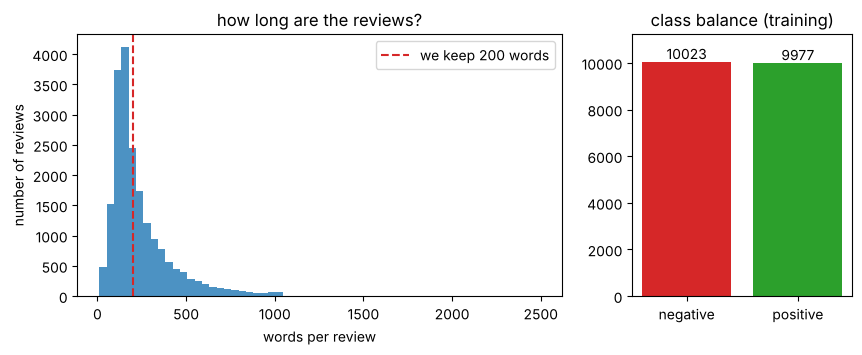

median length: 178 words
share of reviews longer than 200 words: 42.8%
share of word occurrences that are <unknown>: 5.7%


In [4]:
lengths = [len(review) for review in x_train]
fig = it.plot_lengths(lengths, y_train)
save_figure(fig, "01_lengths_and_balance.png")
plt.show()

print("median length:", int(np.median(lengths)), "words")
print(f"share of reviews longer than {it.MAXLEN} words: {np.mean(np.array(lengths) > it.MAXLEN):.1%}")
unknown = sum(token == 2 for review in x_train for token in review) / sum(lengths)
print(f"share of word occurrences that are <unknown>: {unknown:.1%}")

**What to notice.** Most reviews are short or medium (median 178 words) but the tail is long: some have more than 1,000 words.
With our limit of 200 words, 42.8% of the reviews are cut (we keep their last 200 words) and the rest are padded. Only 5.7% of all word occurrences are `<unknown>`,
so a dictionary of 10,000 words covers about 94% of what people write. The classes are balanced (10,023 negative and 9,977 positive), so a model that always says "positive" would be right about half of the time.

*Figure: histogram of review lengths in the training set with our cut-off at 200 words (left) and the number of reviews per class (right).*

### Padding: all reviews the same length

A neural network wants rectangular input, so every review must have exactly 200 numbers. Short reviews are filled with zeros
(*padding*), long ones are cut. We pad and cut at the **front**, so the real text always ends at the last position, the position
the model reads last, right before it decides. (The first version of this project made the same choice by using the default of Keras;
the choice just was not explained.)

In [5]:
x_train_pad, x_val_pad, x_test_pad = it.pad(x_train), it.pad(x_val), it.pad(x_test)

print("shape after padding:", x_train_pad.shape, "(reviews x words)")
short = int(np.argmin(lengths))
print("\nthe shortest review had", lengths[short], "words; after padding it starts with", x_train_pad[short][:5], "and ends with", x_train_pad[short][-5:])

shape after padding: (20000, 200) (reviews x words)

the shortest review had 11 words; after padding it starts with [0 0 0 0 0] and ends with [  60   23 2863 2364  314]


**What to notice.** The zeros are at the front, the real numbers at the back. A model has to learn to ignore the zeros; this works
well in practice but costs a little computing time for the many short reviews.

### Check yourself

1. A word is *not* among the 10,000 most frequent ones. What number does it get?
2. Why is it a problem to feed the model the raw ID numbers as if they were measurements (for example "word 20 is twice word 10")?

<details>
<summary>Answers</summary>


1. The number 2, "unknown". The model cannot tell such words apart.
2. The IDs are only labels sorted by frequency. A model that does arithmetic on them would find relations that do not exist.
   Embeddings fix this: every word gets its own list of coordinates, and relations are learned instead of assumed.

</details>

## 3 · Embeddings: a lookup table that is learned

**Math (light).** The embedding layer owns a table $E$ with 10,000 rows (one per word) and 32 columns (the coordinates).
For a word with number $w$ the layer simply returns row $w$:

$$\mathbf{v}_w = E[w] \qquad E \in \mathbb{R}^{10000 \times 32}$$

- $w$: the ID number of the word;
- $E[w]$: row number $w$ of the table, a list of 32 numbers;
- $\mathbb{R}^{10000 \times 32}$: just means "a table of 10,000 x 32 real numbers".

There is nothing more to it. The 320,000 numbers of $E$ are *parameters* that training adjusts, like all other weights.

In [6]:
model_preview = it.build_model("lstm")
table = model_preview.layers[0].get_weights()[0]
print("embedding table E:", table.shape, "-> 10,000 words x 32 coordinates")
print("coordinates of the word 'great' (first 6 of 32), before any training:")
print(np.round(table[mapping["great"]][:6], 3))

embedding table E: (10000, 32) -> 10,000 words x 32 coordinates
coordinates of the word 'great' (first 6 of 32), before any training:
[ 0.    -0.037 -0.009  0.009  0.019  0.001]


**What to notice.** Before training the coordinates are tiny random numbers, so the map carries no meaning yet.
We will look at the same word again after training.

## 4 · Reading with a notebook: the LSTM

A plain recurrent network (`SimpleRNN`) overwrites its notebook completely at every word, so after 100 words the beginning
is almost forgotten (and training becomes unstable). The **LSTM** adds *gates*, small switches between 0 (closed) and 1 (open)
that decide what is kept.

**Math (light).** At word number $t$ the layer receives the coordinates $x_t$ of the word and its previous state
(the short-term notebook $h_{t-1}$ and the long-term memory $c_{t-1}$):

$$f_t=\sigma(W_f[h_{t-1},x_t]+b_f)\quad i_t=\sigma(W_i[h_{t-1},x_t]+b_i)\quad o_t=\sigma(W_o[h_{t-1},x_t]+b_o)$$
$$\tilde c_t=\tanh(W_c[h_{t-1},x_t]+b_c)\qquad c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t\qquad h_t=o_t\odot\tanh(c_t)$$

- $[h_{t-1},x_t]$: the previous notebook and the current word, glued into one list;
- $W_\cdot$ and $b_\cdot$: weight tables and offsets that are learned (a different pair for every line);
- $\sigma$: the "sigmoid" function, which squeezes any number into the range 0 to 1 (a gate);
- $f_t$ **forget gate** (how much of the old memory to keep), $i_t$ **input gate** (how much of the new idea to write), $o_t$ **output gate** (how much memory to say out loud);
- $\tilde c_t$: the candidate new idea (a number between -1 and 1, from $\tanh$);
- $\odot$: multiply the lists position by position;
- $c_t$: the updated long-term memory, $h_t$: the updated notebook. After the last word, $h$ goes into one final layer that outputs the probability of "positive".

Our model has 32 coordinates per word and 32 memory cells: small enough to train on a CPU in a minute or two per model.

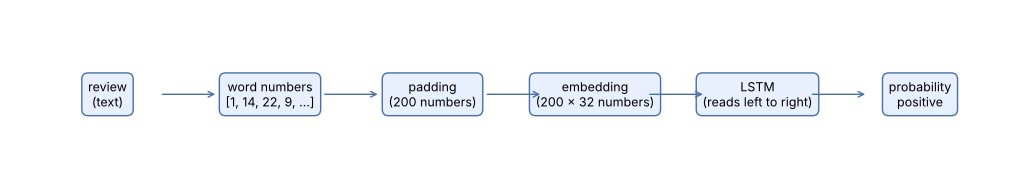

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,353 (1.25 MB)

 Trainable params: 328,353 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
fig = it.plot_pipeline()
save_figure(fig, "01_pipeline.png")
plt.show()
it.build_model("lstm").summary()

**What to notice.** The figure shows the whole path, from text to probability. In the summary, the embedding table has
10,000 x 32 = 320,000 parameters and dominates the model; the LSTM itself has about 8,300 (four sets of weights for the three gates and the candidate idea). Next to the output shape `(None, 1)`: one probability per review (`None` is the batch size).

### Check yourself

1. What does the forget gate $f_t$ do when it is close to 0?
2. Why do we feed the words one after another instead of all at once?

<details>
<summary>Answers</summary>


1. It erases the old long-term memory $c_{t-1}$: the model "forgets" what it had understood so far.
2. Because the order carries meaning ("not good" versus "good, not bad"). The state passed from word to word is how the model remembers what came before.

</details>

## 5 · A reference first: the "just count the words" method

Before we train a neural network we should know what a **simple** method achieves, otherwise a score has no meaning.
*Bag of words* counts how often each of the 10,000 words occurs in a review (the order is thrown away), and logistic regression
learns a weight for every word: positive weights for words like "great", negative for "awful".

In [8]:
from sklearn.linear_model import LogisticRegression

start = time.time()
bag_train, bag_val = it.bag_of_words(x_train), it.bag_of_words(x_val)
counting = LogisticRegression(max_iter=1000).fit(bag_train, y_train)
print(f"bag of words + logistic regression: validation accuracy {counting.score(bag_val, y_val):.4f}   ({time.time() - start:.0f} s)")

bag of words + logistic regression: validation accuracy 0.8796   (5 s)


**What to notice.** Just counting words reaches **0.880** validation accuracy in a few seconds, with no reading and no word order at all.
This is the number our neural networks have to beat. Keep it in mind for the next sections.

## 6 · Training: SimpleRNN (the 2023 idea) versus LSTM

We train two models, identical except for the reading layer: a `SimpleRNN` (what the first version of this project used,
although it was called "LSTM") and a real `LSTM`. Settings: 32 coordinates per word, 32 units, 20,000 training reviews,
at most 6 epochs (one epoch = the model sees every training review once), batch size 64, seed 42. After training, the weights of the epoch with the best
**validation** accuracy are restored (the test set plays no role).

In [9]:
start = time.time()
rnn, rnn_history = it.train("simple_rnn", x_train_pad, y_train, x_val_pad, y_val)
print(f"SimpleRNN trained in {time.time() - start:.0f} s; validation accuracy per epoch:", [round(a, 3) for a in rnn_history["val_accuracy"]])

SimpleRNN trained in 68 s; validation accuracy per epoch: [0.786, 0.636, 0.536, 0.725, 0.77, 0.628]


In [10]:
start = time.time()
lstm, lstm_history = it.train("lstm", x_train_pad, y_train, x_val_pad, y_val)
print(f"LSTM trained in {time.time() - start:.0f} s; validation accuracy per epoch:", [round(a, 3) for a in lstm_history["val_accuracy"]])

LSTM trained in 92 s; validation accuracy per epoch: [0.87, 0.862, 0.83, 0.862, 0.872, 0.857]


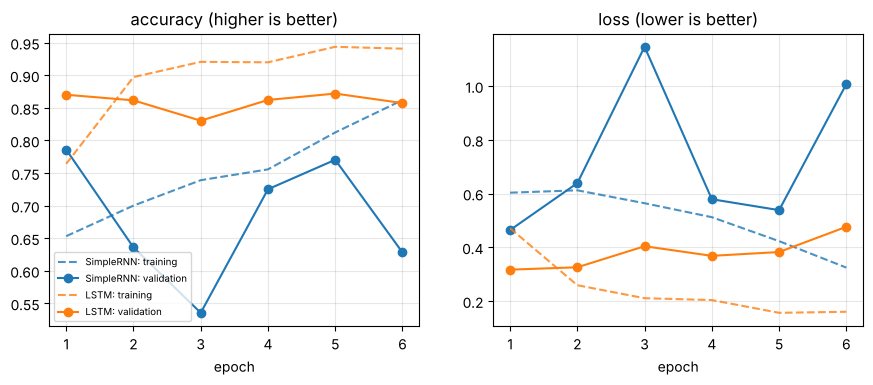

In [11]:
fig = it.plot_history([rnn_history, lstm_history], ["SimpleRNN", "LSTM"])
save_figure(fig, "01_curves.png")
plt.show()

**What to notice.** Dashed lines are the training reviews, solid lines the validation reviews.

- **SimpleRNN (blue):** the validation accuracy swings between 0.54 and 0.79 and the validation loss spikes above 1.1 at epoch 3, while the training accuracy creeps up from 0.65 to 0.86.
  Training is **unstable**. The saved output of the 2023 notebook showed the same kind of jumping (0.64 to 0.81 between epochs).
- **LSTM (orange):** it is good from the first epoch (validation accuracy 0.87) and then stays between 0.83 and 0.87, while its training accuracy rises to about 0.94.
  The validation loss is lowest in epoch 1 (about 0.32) and then *rises* to about 0.48 while the training loss falls to about 0.16: the LSTM starts to **memorise** the training reviews after the first epoch.
- Restored at the end: the epoch with the best validation accuracy, epoch 1 for the SimpleRNN (0.786) and epoch 5 for the LSTM (0.872). Choosing by validation *loss* instead would pick epoch 1 for the LSTM; the validation accuracy differs by only about 0.002 between these two epochs.

*Figure: accuracy (left) and loss (right) per epoch for the SimpleRNN and the LSTM; dashed = training, solid with dots = validation.*

### Check yourself

1. The LSTM's training accuracy keeps rising but its validation accuracy does not. What is this called, and why can it not be seen in the training numbers alone?
2. Why do we restore the weights of the best *validation* epoch rather than the best *test* epoch?

<details>
<summary>Answers</summary>


1. Overfitting (memorising). The training numbers only measure how well the model knows the reviews it has already seen.
2. Choosing by the test score would use the test set to make a decision, so it would no longer be an independent, honest exam.

</details>

## 7 · What did the embedding learn?

After training, the coordinates of words are no longer random. For a few words we list the words whose coordinates point in the most similar direction
(cosine similarity: 1 means the same direction, 0 unrelated).

> **Predict:** will the neighbours of "great" be positive words?

great      comments (0.96), tsui (0.94), stance (0.93), tribute (0.93), prophet (0.93), marty (0.93)
awful      remotely (0.99), unwatchable (0.99), worst (0.98), mst3k (0.98), mess (0.98), olds (0.98)
boring     mental (0.97), poor (0.97), skipping (0.97), annoying (0.97), inappropriate (0.97), generous (0.97)
excellent  underrated (0.98), horrors (0.98), vengeance (0.98), paulie (0.98), melancholy (0.97), heavens (0.97)


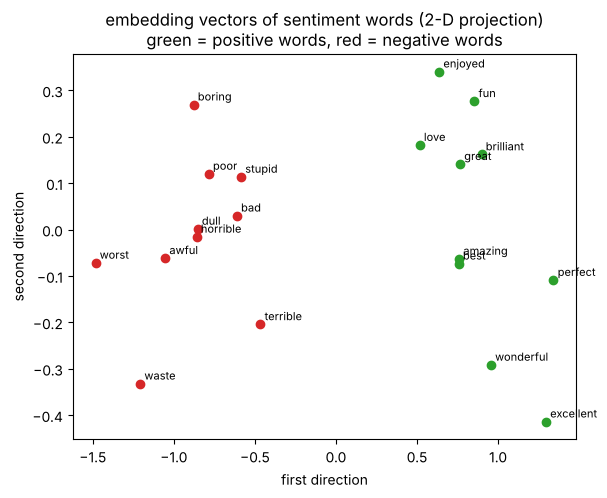

In [12]:
matrix = lstm.layers[0].get_weights()[0]
for word in ["great", "awful", "boring", "excellent"]:
    neighbours = it.cosine_neighbours(matrix, mapping, inverse, word)
    print(f"{word:10s}", ", ".join(f"{w} ({s:.2f})" for w, s in neighbours))

positive = ["great", "excellent", "wonderful", "amazing", "perfect", "best", "love", "enjoyed", "brilliant", "fun"]
negative = ["awful", "terrible", "boring", "worst", "bad", "waste", "poor", "stupid", "dull", "horrible"]
fig = it.plot_embedding_map(matrix, mapping, positive, negative)
save_figure(fig, "01_embedding_map.png")
plt.show()

**What to notice.** The picture is mixed, and it is worth being honest about that.

- Some neighbour lists make sense: *awful* is close to *unwatchable*, *worst* and *mess*; *boring* is close to *poor* and *annoying*.
- Others do not: *great* has *comments*, *tsui* and *stance* as neighbours, and *excellent* has *underrated*, *horrors* and *vengeance*.
- All similarities are very high (0.93 to 0.99): after short training on 20,000 reviews the vectors share a large common component, so the numbers separate words only weakly.
- In the map, where we chose ten positive and ten negative words ourselves, the first direction separates the two groups: negative words on the left, positive words on the right. The projection was computed from these 20 words only, so it shows that *sentiment is one direction the model uses*, not that it understands words in general.

*Figure: the coordinates of 20 hand-picked sentiment words, flattened to two dimensions with PCA (green = positive, red = negative).*

## 8 · The final grade (test set, used once)

Only now do we open the 25,000 locked test reviews, once per model.

In [13]:
bag_test = it.bag_of_words(x_test)
results = {"bag of words + logistic regression": counting.score(bag_test, y_test)}
for name, model in [("SimpleRNN", rnn), ("LSTM", lstm)]:
    results[name] = model.evaluate(x_test_pad, y_test, batch_size=256, verbose=0)[1]
for name, accuracy in results.items():
    print(f"{name:38s} test accuracy {accuracy:.4f}")
print("\nthe first version of this project (2023, SimpleRNN, evaluated on the test set during training): 0.7492")

bag of words + logistic regression     test accuracy 0.8572
SimpleRNN                              test accuracy 0.7966
LSTM                                   test accuracy 0.8626

the first version of this project (2023, SimpleRNN, evaluated on the test set during training): 0.7492


**What to notice.**

- The **LSTM (0.8626)** and the **word-counting baseline (0.8572)** are about half a percentage point apart on 25,000 test reviews, from one run with one seed. We cannot claim the LSTM is better: **in this setup the simple method is about as good.**
- The **SimpleRNN (0.7966)** is clearly behind, in line with its unstable curves.
- The 2023 value (0.7492) is not directly comparable (80 words per review, a different vocabulary and size, 15 epochs, and the test set was used during training), but it was lower than every number above.
- Why the LSTM does not win clearly is not something we tested. Possible reasons: sentiment is largely carried by single words ("great", "awful"), so word order helps less than we might expect; our model is small and the reviews are cut to 200 words; we train for few epochs.

Notebook 02 asks whether a model that was pre-trained on a huge amount of text does better.

## 9 · Try your own sentences

A model should not only be graded on a data set. Let us ask it about sentences we wrote ourselves.

> **Predict:** which of the four sentences below will the LSTM get wrong?

In [14]:
sentences = [
    "this movie was great and I loved every minute of it",
    "a boring, predictable mess and a waste of time",
    "this movie was not good at all",
    "I expected a terrible film but it turned out to be wonderful",
]
batch = it.pad([it.encode(s, mapping) for s in sentences])
for sentence, probability in zip(sentences, lstm.predict(batch, verbose=0)[:, 0]):
    print(f"p(positive) = {probability:.2f}   {sentence}")

p(positive) = 0.94   this movie was great and I loved every minute of it
p(positive) = 0.00   a boring, predictable mess and a waste of time
p(positive) = 0.56   this movie was not good at all
p(positive) = 0.84   I expected a terrible film but it turned out to be wonderful


**What to notice.** Sentences 1 and 2 are easy (0.94 and 0.00). Sentence 3, *"this movie was not good at all"*, is the interesting one: the model gives it 0.56, so it leans slightly **positive** for a clearly negative sentence. It saw "good" and did not fully handle the negation.
Sentence 4 (*"I expected a terrible film but it turned out to be wonderful"*) is on the right side (0.84), but we cannot tell whether the model understood the "but" or simply reacted to "wonderful".
Four sentences prove nothing; they show how to probe a model and where to look (negation). Notebook 03 will show which words drive a prediction.

## 10 · Common mistakes

- **Judging a model without a simple reference.** A score of 87% means little until you know that counting words gives about the same.
- **Using the test set while training or to choose settings.** The first version of this project did that (`validation_data=X_test`); the test number is then no longer a fair exam.
- **Padding at the wrong end or forgetting to ignore the padding.** Know which end holds the real text.
- **Calling a `SimpleRNN` an LSTM.** They are different layers; the SimpleRNN is much harder to train on long texts.
- **Trusting one run.** Validation accuracy jumps from epoch to epoch (see the curves); a difference of a point or two between single runs is within the noise.

## 11 · Recap

- Text becomes numbers in two steps: word to ID number, then ID to a learned list of coordinates (the embedding).
- An LSTM reads the coordinates in order and keeps a gated memory; at the end one number says how positive the review is.
- A simple baseline (counting words) is a sanity check that must be reported next to the neural model, and here it is hard to beat.

**Next:** notebook 02 compares the LSTM with a small pretrained language model on a fixed subset of reviews, in an honest results table.